In [13]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch
import pandas as pd

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [14]:
def compute_norm_change(signal, signal_ref):
    pct_change = ((signal - signal_ref) / signal_ref) * 100
    return torch.norm(pct_change).item()

In [15]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [16]:
# Define the MPA model characteristics, Transmitter and Receiver size and position
# and the waveform to be used. 
times = torch.logspace(-5, -3, 32)
fwrTD = Forward.mpa(tx, rx, times, filterfunc=recfilter)


frqs = torch.logspace(3,6,51)
fwrFD = ForwardFD.mpa(tx, rx, frqs, filterfunc=recfilter)

c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [17]:
# Define the model parameters fopr the MPA model. 


second_layer_rhos = torch.tensor([500, 100, 50, 10], dtype=torch.double)

thickness = torch.tensor([30], dtype=torch.double)
rho = torch.tensor([50, 1000], dtype=torch.double)
# Ip values for the MPA model in the second layer
phi_max_values = torch.logspace(start=torch.log10(torch.tensor(1)), 
                            end=torch.log10(torch.tensor(1000.0)), 
                            steps=10, dtype=torch.double)/1e3

tau_phi_values = torch.logspace(start=torch.log10(torch.tensor(1e-5)),
                            end=torch.log10(torch.tensor(1e-2)), 
                            steps=10, dtype=torch.double)

c_values = torch.tensor([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], dtype=torch.double)

phi_2 = torch.tensor(0.001, dtype=torch.double)
tau_phi_2 = 1e-4
c_2 = 0.5


# Colormap
cmap = cm.get_cmap('rainbow')
norm = mcolors.Normalize(vmin=float(c_values.min()), vmax=float(c_values.max()))
sm = cm.ScalarMappable(cmap=cmap, norm=norm)



C:\Users\au653994\AppData\Local\Temp\ipykernel_8604\3884650956.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow')


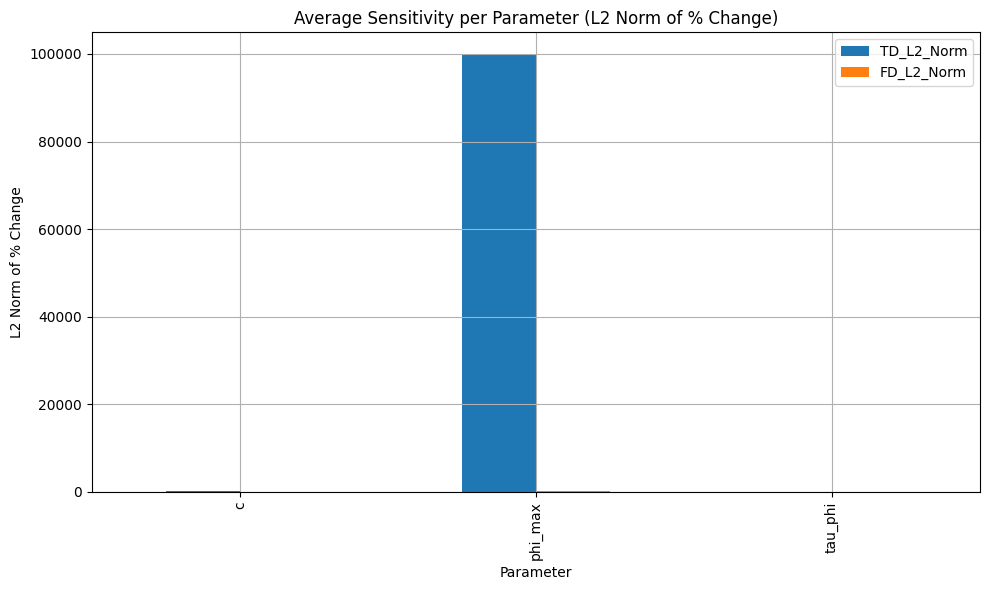

In [18]:
# Reference values
phi_ref = torch.tensor([phi_max_values[0].item(), phi_2.item()])
tau_phi_ref = torch.tensor([tau_phi_values[0].item(), tau_phi_2])
c_ref = torch.tensor([c_values[0].item(), c_2])

dbdt_ref = fwrTD(rho, phi_ref, tau_phi_ref, c_ref, thickness)
dbdf_ref = fwrFD(rho, phi_ref, tau_phi_ref, c_ref, thickness)

results = []


for phi0 in phi_max_values:
    phi = torch.tensor([phi0.item(), phi_2.item()])
    dbdt = fwrTD(rho, phi, tau_phi_ref, c_ref, thickness)
    dbdf = fwrFD(rho, phi, tau_phi_ref, c_ref, thickness)
    results.append(["phi_max", phi0.item(), compute_norm_change(dbdt, dbdt_ref), compute_norm_change(dbdf, dbdf_ref)])

for tau0 in tau_phi_values:
    tau = torch.tensor([tau0.item(), tau_phi_2])
    dbdt = fwrTD(rho, phi_ref, tau, c_ref, thickness)
    dbdf = fwrFD(rho, phi_ref, tau, c_ref, thickness)
    results.append(["tau_phi", tau0.item(), compute_norm_change(dbdt, dbdt_ref), compute_norm_change(dbdf, dbdf_ref)])

for c0 in c_values:
    c = torch.tensor([c0.item(), c_2])
    dbdt = fwrTD(rho, phi_ref, tau_phi_ref, c, thickness)
    dbdf = fwrFD(rho, phi_ref, tau_phi_ref, c, thickness)
    results.append(["c", c0.item(), compute_norm_change(dbdt, dbdt_ref), compute_norm_change(dbdf, dbdf_ref)])

df = pd.DataFrame(results, columns=["Parameter", "Value", "TD_L2_Norm", "FD_L2_Norm"])
mean_sensitivity = df.groupby("Parameter")[["TD_L2_Norm", "FD_L2_Norm"]].mean()

# Plot
mean_sensitivity.plot(kind='bar', figsize=(10, 6), title="Average Sensitivity per Parameter (L2 Norm of % Change)")
plt.ylabel("L2 Norm of % Change")
plt.grid(True)
plt.tight_layout()
plt.show()


